# Homework #3 — Exploratory Data Analysis (Intermediate Report)
**Team ID:** 16 &nbsp;|&nbsp; **Dataset:** Reddit — `r/singularity`, `r/ArtificialInteligence`, `r/aiwars`, `r/doomer` (collected in HW#2, bots filtered)

> **Time spent on this homework:** `4 hours` &nbsp;**

**Status:** preliminary report (deadline 06/10). It covers the dataset overview, the questions/hypotheses we want to test, and the basic distributions. Sections marked *Next steps* are planned for week 2.

## 0. Setup
Only the columns needed for EDA are read from the (very wide) CSVs — 74 columns for comments and 120 for submissions in the raw data — which keeps memory use manageable for ~1.6M comments.

In [1]:
import re, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (11, 5),
                     "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11})

COMMENTS_CSV = "cleaned_combined_reddit_comments.csv"
SUBS_CSV     = "cleaned_combined_reddit_submissions.csv"

In [2]:
def to_dt(s):
    # created_utc is stored as epoch seconds; fall back to parsing if it is already text
    return pd.to_datetime(s, unit="s") if pd.api.types.is_numeric_dtype(s) else pd.to_datetime(s, errors="coerce")

read_kw = dict(low_memory=False, lineterminator="\n", on_bad_lines="skip", encoding="utf-8")

def load(path, wanted):
    # read only the needed columns; silently skip any that the file does not have
    have = pd.read_csv(path, nrows=0, **read_kw).columns   # same parser settings as the full read
    return pd.read_csv(path, usecols=[c for c in wanted if c in have], **read_kw)

comments = load(COMMENTS_CSV, ["id","author","body","created_utc","subreddit","score","link_id","parent_id","total_awards_received"])
subs = load(SUBS_CSV, ["id","author","title","selftext","created_utc","subreddit","score","upvote_ratio","num_comments","url","total_awards_received"])
for d in (comments, subs):
    d["created_utc"] = to_dt(d["created_utc"])
    d["date"] = d["created_utc"].dt.floor("D")
    d["hour"] = d["created_utc"].dt.hour
    d["weekday"] = d["created_utc"].dt.dayofweek

# subreddits ordered by total activity -> one consistent colour per subreddit in every chart
order = (comments["subreddit"].value_counts().add(subs["subreddit"].value_counts(), fill_value=0)
         .sort_values(ascending=False).index.tolist())
PAL = dict(zip(order, sns.color_palette("Dark2", len(order))))
print("Subreddits:", order)

Subreddits: ['singularity', 'aiwars', 'ArtificialInteligence', 'doomer']


## 1. Overview: what do we have?

In [3]:
def summary(d, name):
    return pd.Series({
        "records": f"{len(d):,}",
        "first record (UTC)": d["created_utc"].min().strftime("%Y-%m-%d %H:%M"),
        "last record (UTC)": d["created_utc"].max().strftime("%Y-%m-%d %H:%M"),
        "days covered": (d["created_utc"].max() - d["created_utc"].min()).days + 1,
        "subreddits": d["subreddit"].nunique(),
        "unique authors": f"{d['author'].nunique():,}",
        "memory (MB, loaded cols)": f"{d.memory_usage(deep=True).sum()/2**20:,.0f}",
    }, name=name)

display(pd.concat([summary(subs, "Submissions"), summary(comments, "Comments")], axis=1))
print(f"Average comments per submission in the data: {len(comments)/len(subs):.1f}")

,Submissions,Comments
records,"65,582","1,617,751"
first record (UTC),2024-09-01 00:11,2024-09-01 00:00
last record (UTC),2025-05-31 23:53,2025-05-31 23:59
days covered,273,273
subreddits,4,4
unique authors,"31,682","156,468"
"memory (MB, loaded cols)",72,"1,088"


Average comments per submission in the data: 24.7


**What we have.** Two linked tables: *submissions* (posts: title, text, link, score, upvote ratio, comment count) and *comments* (body, score, `link_id` = the post it belongs to, `parent_id` = the item it replies to). From the HW#2 exploration: **1,617,751 comments** and **65,582 submissions** in four AI-related communities, starting on 2024-09-01. Comments outnumber posts ~25 : 1, so most of the content is discussion under posts.

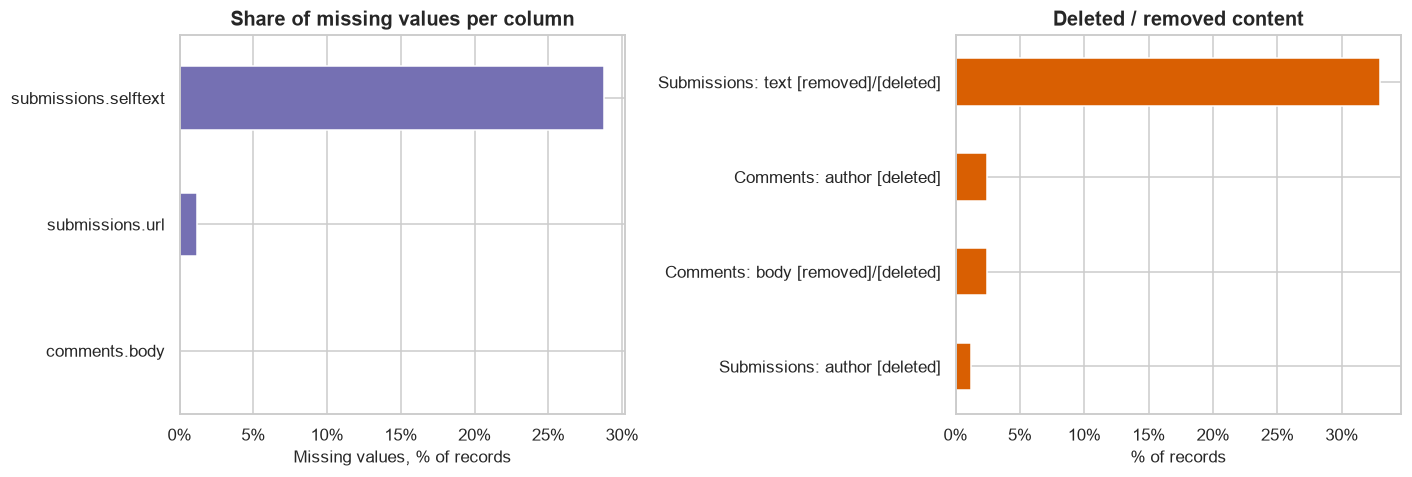

In [4]:
# Data quality: missing values and removed/deleted content
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

miss = pd.concat([
    (subs.isna().mean()*100).rename(lambda c: f"submissions.{c}"),
    (comments.isna().mean()*100).rename(lambda c: f"comments.{c}")]).sort_values()
miss = miss[miss > 0]
miss.plot.barh(ax=axes[0], color="#7570b3")
axes[0].set(title="Share of missing values per column", xlabel="Missing values, % of records", ylabel="")

deleted = pd.Series({
    "Submissions: author [deleted]": (subs["author"]=="[deleted]").mean()*100,
    "Submissions: text [removed]/[deleted]": subs["selftext"].isin(["[removed]","[deleted]"]).mean()*100,
    "Comments: author [deleted]": (comments["author"]=="[deleted]").mean()*100,
    "Comments: body [removed]/[deleted]": comments["body"].isin(["[removed]","[deleted]"]).mean()*100,
})
deleted.sort_values().plot.barh(ax=axes[1], color="#d95f02")
axes[1].set(title="Deleted / removed content", xlabel="% of records", ylabel="")
for ax in axes: ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
plt.tight_layout(); plt.show()

> **Observation:** _fill in after running (e.g. which columns are mostly empty; `selftext` is empty for link/image posts, so ~29% missing is expected; how large the `[deleted]`/`[removed]` share is — they carry no usable author/text and will be excluded from author- and text-level analysis)._

## 2. Questions and hypotheses we want to test

### Thematic hypotheses

**H1. Fatalism paradox.** AI optimists and AI pessimists use the same language of lost control over the future. Only the emotion differs: excitement versus despair.
*Test:* Compare how often "inevitable / fate / no way to stop it / end" words appear in both groups, and how often passive voice with humanity as the subject appears. Then compare sentiment.

**H2. AI as religion.** AI discussion drifts from engineering to religious language. Jailbreaking looks like liberation, model updates like divine intervention, alignment like salvation.
*Test:* Use topic modelling and Word2Vec to measure how close "AGI, weights, prompt" sit to "god, soul, awakening, salvation". Check whether religious wording grows around big model releases.

**H3. Class conflict, not human vs. machine.** In AI-art debates, hostility is aimed less at the tools than at the people using them ("prompters", "tech bros"), seen as profiting from others' work.
*Test:* Extract named entities, split them into tools and social groups, and compare toxicity and scores for each. Check a hand-labelled sample of about 200 comments.

**H4. Fear of "grey goo".** Fear of killer robots is fading. The main worry becomes a boring internet full of AI-generated junk ("AI slop") where real people are hard to find.
*Test:* Track monthly frequency of physical-threat words (extinction, weapons) against degradation words (slop, fake, bots, garbage). Needs at least 6 months of data.

**H5. Proof of humanity.** To look human, users deliberately write imperfectly: typos, slang, aggression, personal confessions.
*Test:* Measure readability, spelling errors and slang density, and correlate them with anti-AI content. Compare comments accused of "sounding like ChatGPT" with normal ones.

### Hypotheses from activity and structure

**H6. Debate communities have longer, harsher threads.** They should show more comments per post and more downvoted comments. *(tested in §4, §6)*
*Test:* Compare comments per post, thread depth, and the share of negative-score comments.

**H7. A few users produce most of the content.** Activity is heavy-tailed, with a few news-curator accounts and possibly leftover bots. *(§5)*
*Test:* Plot the distribution of items per author and the share written by the top 1%. Check top accounts for bot signs such as regular timing and near-duplicate titles.

**H8. Spikes follow real-world AI events.** Model releases, major news and awards should cause volume peaks, and different events excite different communities. *(§3)*
*Test:* Detect anomalous days, match them to a timeline of events, and extract the top phrases on each spike day.

**H9. Communities share some, but not all, of their audience.** Similar communities should overlap heavily in users, while niche ones stay insular. *(§5)*
*Test:* Compute author overlap between each pair of communities.

**H10. Daily rhythm reveals audience geography.** Peak hours and weekday patterns should differ between communities. *(§3)*
*Test:* Build hour-by-weekday heatmaps per community and compare them.

### Extra ideas to explore
- **Engagement drivers:** do title length, question marks or link posts predict score and comment count? *(§6, §7)*
- **Controversy:** which posts have a low upvote ratio but many comments? *(§6)*
- **Deleted content:** does the share of removed content change over time, and could it signal moderation waves? *(§1)*
- **Newcomers vs. veterans:** do first-time authors differ in tone, length and score? *(week 2)*
- **Data completeness:** how many comments belong to posts outside our time window? *(§8)*

> H1–H5 need text mining (sentiment, topic models, embeddings, NER) and are planned for week 2. H6–H10 and the extra ideas are already explored with basic distributions below.

## 3. Activity over time
**Expectation.** Activity is not uniform: it should show weekly seasonality and spikes around major AI news. Dashed lines below mark *candidate* real-world events (only those inside our time window are drawn; to be verified/extended in week 2).

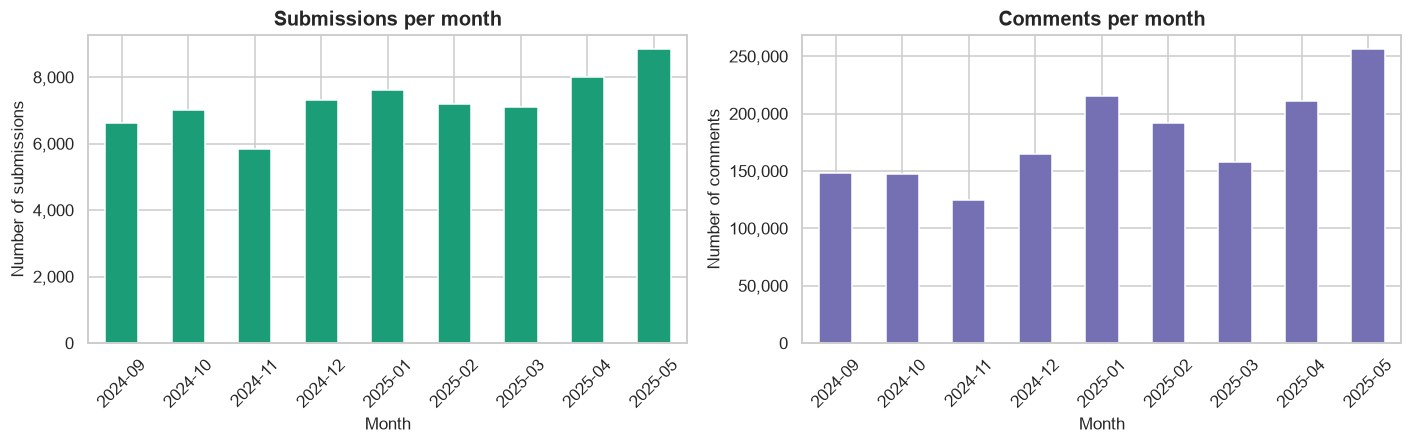

In [5]:
EVENTS = {  # candidate events to correlate with spikes (verify dates in week 2)
    "2024-09-12": "OpenAI o1-preview",
    "2024-10-08": "Nobel Physics (AI)",
    "2024-10-22": "Claude 3.5 Sonnet (new)",
    "2024-12-20": "OpenAI o3 announced",
    "2025-01-20": "DeepSeek-R1",
    "2025-03-25": "GPT-4o image generation",
}
def add_events(ax, d0, d1, ymax_frac=0.98):
    for i, (d, label) in enumerate(EVENTS.items()):
        t = pd.Timestamp(d)
        if d0 <= t <= d1:
            ax.axvline(t, color="grey", ls="--", lw=0.9, alpha=.8)
            ax.text(t, ax.get_ylim()[1]*ymax_frac, " "+label, rotation=90, va="top", ha="right", fontsize=8, color="dimgrey")

# 3.1 monthly volume
m_c = comments.groupby(comments["created_utc"].dt.to_period("M")).size()
m_s = subs.groupby(subs["created_utc"].dt.to_period("M")).size()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
m_s.plot.bar(ax=axes[0], color="#1b9e77"); axes[0].set(title="Submissions per month", xlabel="Month", ylabel="Number of submissions")
m_c.plot.bar(ax=axes[1], color="#7570b3"); axes[1].set(title="Comments per month", xlabel="Month", ylabel="Number of comments")
for ax in axes:
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v,_: f"{v:,.0f}")); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

> **Observation (activity trend):** _fill in (growth/decline trend; partial first/last month if any)._

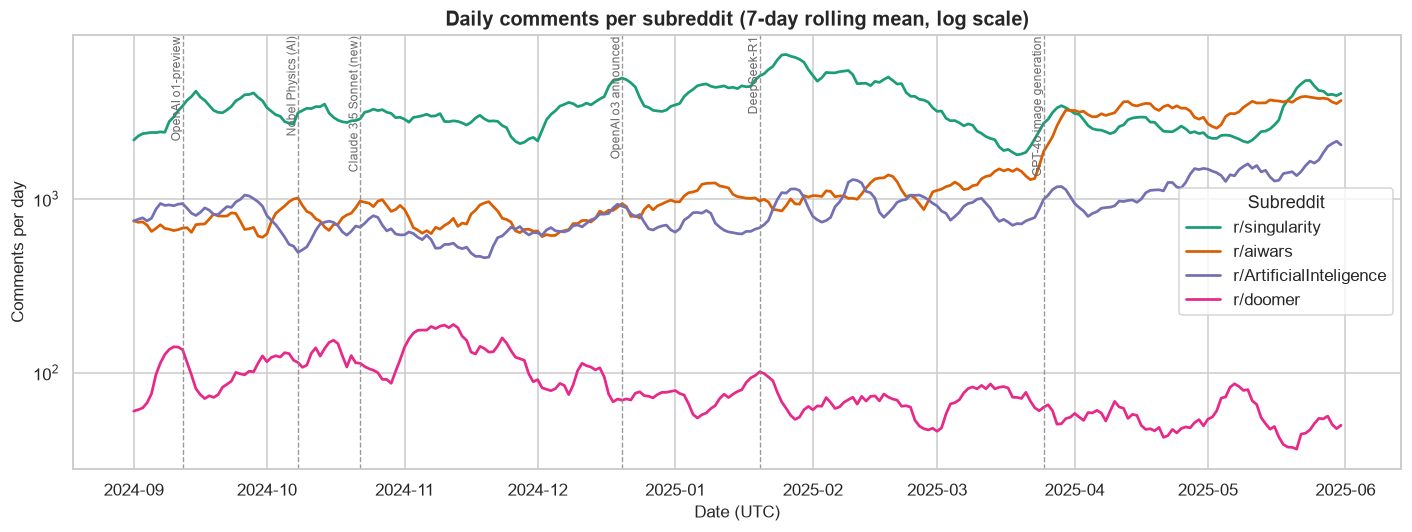

In [6]:
# 3.2 daily comments per subreddit, 7-day rolling mean (log y so small subreddits stay visible)
daily_c = comments.groupby(["date","subreddit"]).size().unstack(fill_value=0)[order]
fig, ax = plt.subplots(figsize=(13, 5))
for s in order:
    ax.plot(daily_c.index, daily_c[s].rolling(7, center=True, min_periods=1).mean(), label=f"r/{s}", color=PAL[s], lw=1.8)
ax.set_yscale("log")
ax.set(title="Daily comments per subreddit (7-day rolling mean, log scale)", xlabel="Date (UTC)", ylabel="Comments per day")
add_events(ax, daily_c.index.min(), daily_c.index.max())
ax.legend(title="Subreddit"); plt.tight_layout(); plt.show()

> **Observation (H8 – volume per subreddit):** _fill in (which subreddit dominates; do all four move together? which dates spike and what happened then?)._

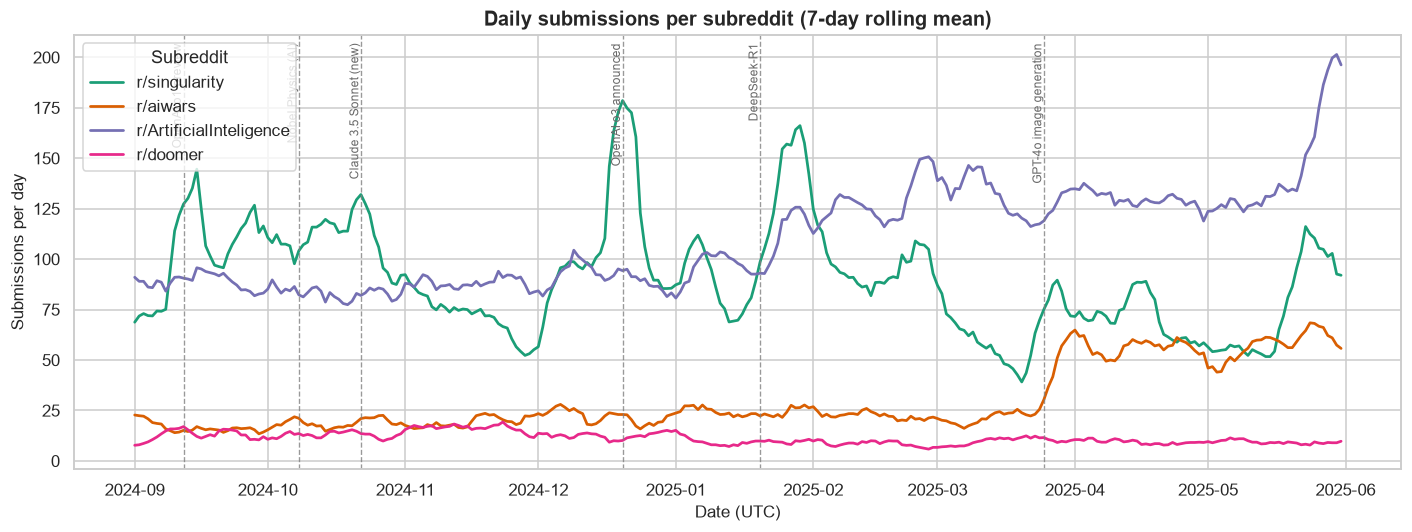

In [7]:
# 3.3 daily submissions per subreddit
daily_s = subs.groupby(["date","subreddit"]).size().unstack(fill_value=0)[order]
fig, ax = plt.subplots(figsize=(13, 5))
for s in order:
    ax.plot(daily_s.index, daily_s[s].rolling(7, center=True, min_periods=1).mean(), label=f"r/{s}", color=PAL[s], lw=1.8)
ax.set(title="Daily submissions per subreddit (7-day rolling mean)", xlabel="Date (UTC)", ylabel="Submissions per day")
add_events(ax, daily_s.index.min(), daily_s.index.max())
ax.legend(title="Subreddit"); plt.tight_layout(); plt.show()

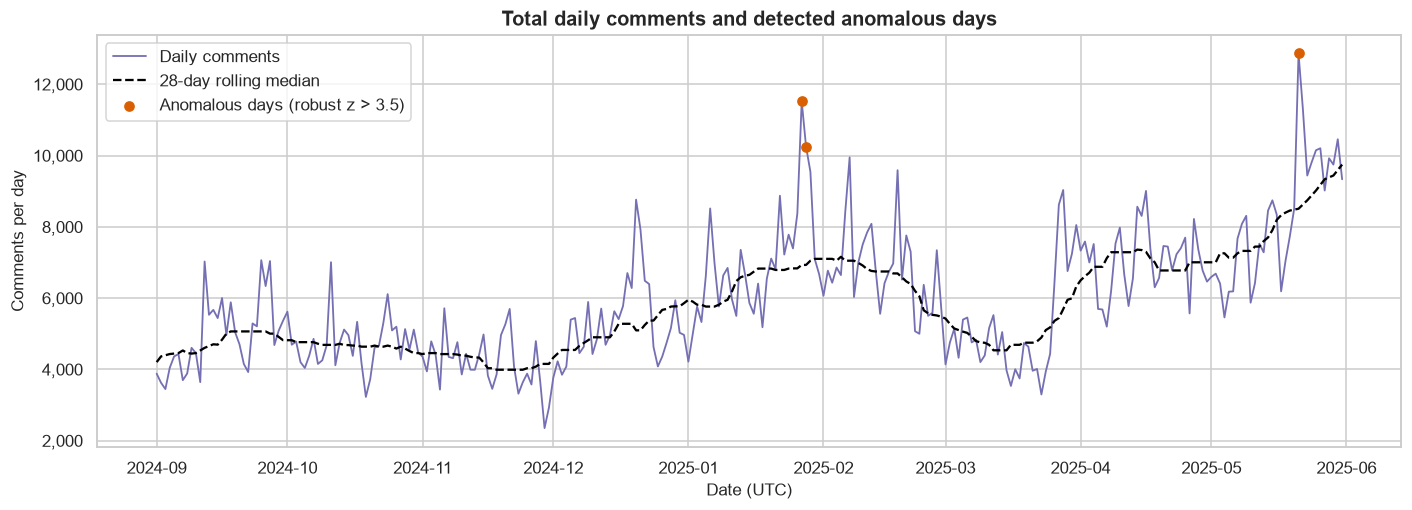

Anomalous days: ['2025-01-27', '2025-01-28', '2025-05-21']


In [8]:
# 3.4 anomaly detection on total daily comments: robust z-score vs. 28-day rolling median
tot = daily_c.sum(axis=1)
med = tot.rolling(28, center=True, min_periods=7).median()
mad = (tot - med).abs().rolling(28, center=True, min_periods=7).median()
z = 0.6745 * (tot - med) / mad.replace(0, np.nan)
spikes = z[z > 3.5].index
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(tot.index, tot, color="#7570b3", lw=1.2, label="Daily comments")
ax.plot(med.index, med, color="black", lw=1.5, ls="--", label="28-day rolling median")
ax.scatter(spikes, tot[spikes], color="#d95f02", zorder=3, label="Anomalous days (robust z > 3.5)")
ax.set(title="Total daily comments and detected anomalous days", xlabel="Date (UTC)", ylabel="Comments per day")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v,_: f"{v:,.0f}")); ax.legend()
plt.tight_layout(); plt.show()
print("Anomalous days:", [d.strftime("%Y-%m-%d") for d in spikes] or "none detected")

> **Observation (H8 – spikes follow real-world events):** _fill in (list the spike dates and match each with a real-world event — this is the main week-2 task)._

**Daily rhythm (H10).** Reddit is global, so we look at the share of each subreddit's comments by hour (UTC) and at the weekday × hour pattern.

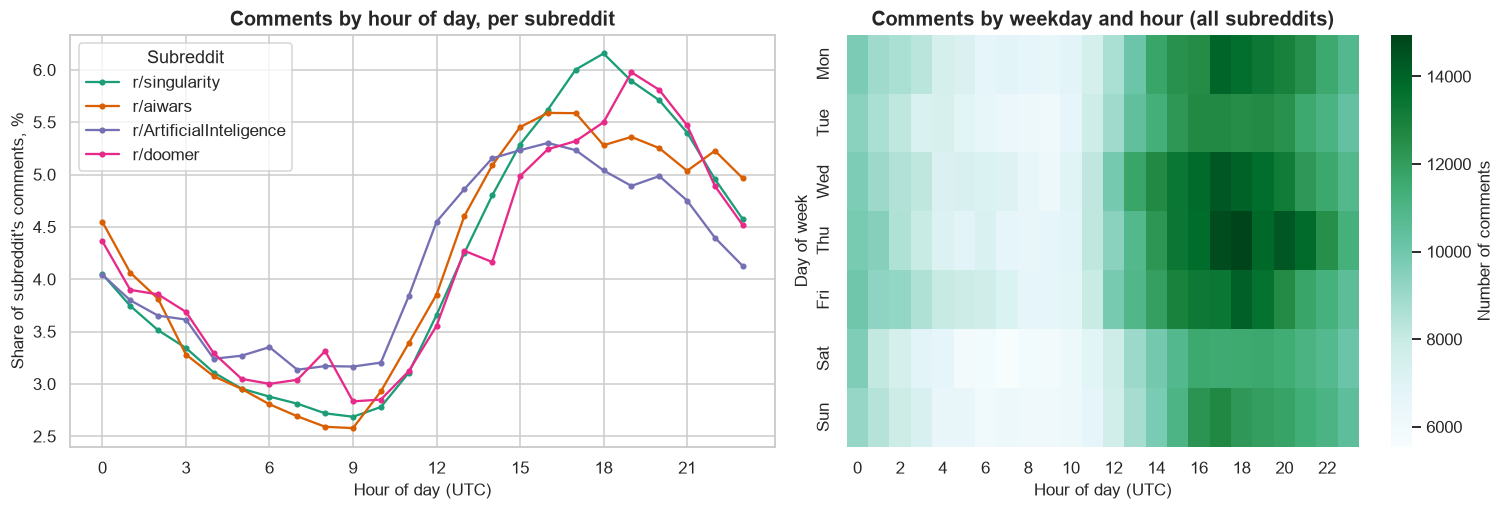

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios":[1.1,1]})
hour = comments.groupby(["hour","subreddit"]).size().unstack(fill_value=0)[order]
hour = hour / hour.sum() * 100
for s in order: axes[0].plot(hour.index, hour[s], marker="o", ms=3, label=f"r/{s}", color=PAL[s])
axes[0].set(title="Comments by hour of day, per subreddit", xlabel="Hour of day (UTC)", ylabel="Share of subreddit's comments, %")
axes[0].set_xticks(range(0, 24, 3)); axes[0].legend(title="Subreddit")

hm = comments.groupby(["weekday","hour"]).size().unstack(fill_value=0).reindex(index=range(7), columns=range(24), fill_value=0)
hm.index = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]
sns.heatmap(hm, cmap="BuGn", ax=axes[1], cbar_kws={"label":"Number of comments"})
axes[1].set(title="Comments by weekday and hour (all subreddits)", xlabel="Hour of day (UTC)", ylabel="Day of week")
plt.tight_layout(); plt.show()

> **Observation (H10 – daily rhythm):** _fill in (peak hours — which time zone do they suggest? weekday vs weekend difference?)._

## 4. Subreddits: size and engagement
**H6.** Same topic, different cultures: we expect the debate communities to generate much more discussion per post than the general ones.

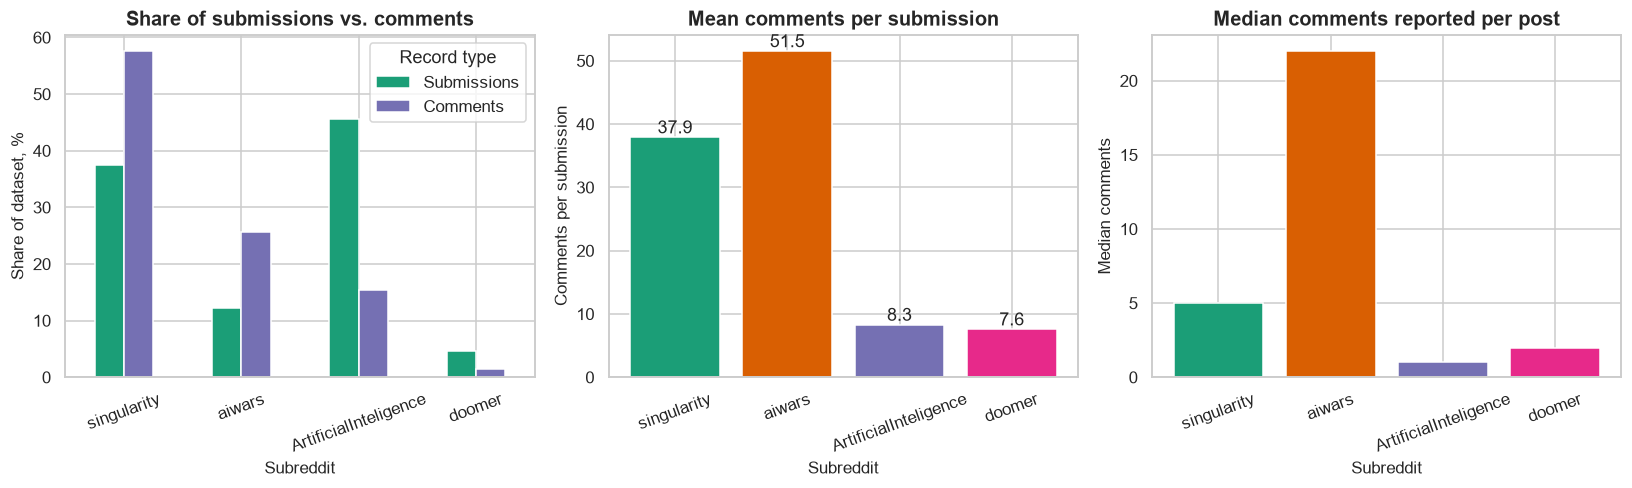

In [10]:
share = pd.DataFrame({"Submissions": subs["subreddit"].value_counts(normalize=True),
                      "Comments": comments["subreddit"].value_counts(normalize=True)}).loc[order]*100
cpp = (comments["subreddit"].value_counts() / subs["subreddit"].value_counts()).loc[order]   # comments per submission
med_nc = subs.groupby("subreddit")["num_comments"].median().loc[order]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
share.plot.bar(ax=axes[0], color=["#1b9e77","#7570b3"], rot=20)
axes[0].set(title="Share of submissions vs. comments", xlabel="Subreddit", ylabel="Share of dataset, %")
axes[0].legend(title="Record type")
axes[1].bar(cpp.index, cpp.values, color=[PAL[s] for s in cpp.index])
axes[1].set(title="Mean comments per submission", xlabel="Subreddit", ylabel="Comments per submission")
axes[1].tick_params(axis="x", rotation=20)
for i, v in enumerate(cpp.values): axes[1].text(i, v, f"{v:.1f}", ha="center", va="bottom")
axes[2].bar(med_nc.index, med_nc.values, color=[PAL[s] for s in med_nc.index])
axes[2].set(title="Median comments reported per post", xlabel="Subreddit", ylabel="Median comments")
axes[2].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

**Already visible from the HW#2 counts:** `singularity` produces 57.6% of comments but only 37.5% of posts; `ArtificialInteligence` is the opposite (45.6% of posts, 15.3% of comments, ≈ 8 comments/post vs ≈ 38 in `singularity` and ≈ 52 in `aiwars`). This supports **H6**: the debate-focused communities produce the most threaded interactions. `doomer` is tiny (1.4% of comments).

## 5. Authors
**H7.** Participation inequality is typical for online communities (a few very active users, a long tail of one-time posters).

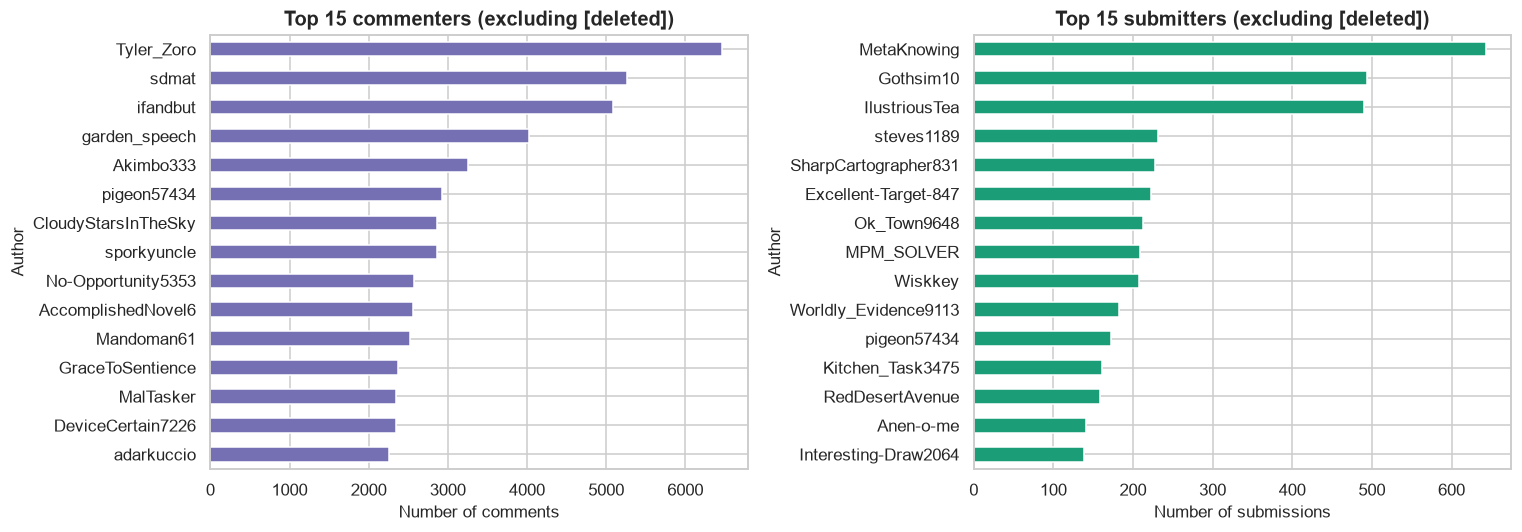

In [11]:
c_auth = comments[comments["author"]!="[deleted]"]["author"].value_counts()
s_auth = subs[subs["author"]!="[deleted]"]["author"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
c_auth.head(15)[::-1].plot.barh(ax=axes[0], color="#7570b3")
axes[0].set(title="Top 15 commenters (excluding [deleted])", xlabel="Number of comments", ylabel="Author")
s_auth.head(15)[::-1].plot.barh(ax=axes[1], color="#1b9e77")
axes[1].set(title="Top 15 submitters (excluding [deleted])", xlabel="Number of submissions", ylabel="Author")
plt.tight_layout(); plt.show()

> **Observation:** _fill in (HW#2 showed e.g. `Tyler_Zoro`, `sdmat` among top commenters and `MetaKnowing`, `Gothsim10`, `IlustriousTea` among top submitters — are the top posters news-aggregators? any remaining bots?)._

Comments: top 1% of authors write 39.8% of items; 49.3% of authors wrote just one item
Submissions: top 1% of authors write 22.5% of items; 73.6% of authors wrote just one item


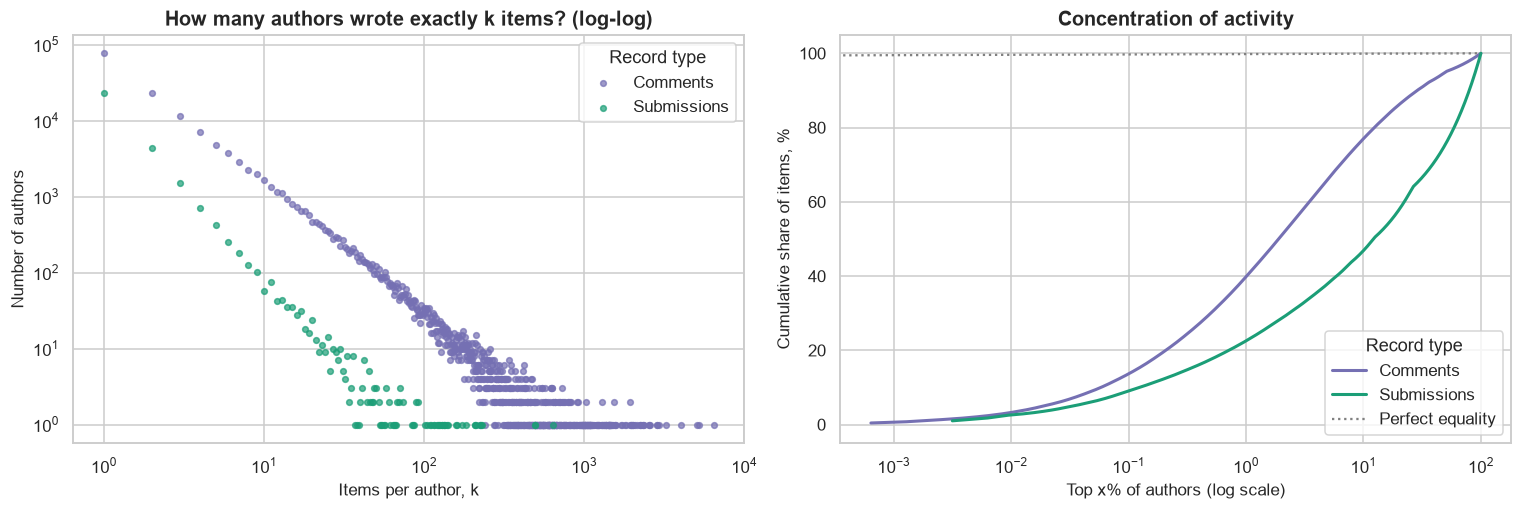

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# distribution of activity per author (log-log)
for name, ser, col in [("Comments", c_auth, "#7570b3"), ("Submissions", s_auth, "#1b9e77")]:
    vc = ser.value_counts().sort_index()
    axes[0].scatter(vc.index, vc.values, s=14, alpha=.7, label=name, color=col)
axes[0].set(xscale="log", yscale="log", title="How many authors wrote exactly k items? (log-log)",
            xlabel="Items per author, k", ylabel="Number of authors")
axes[0].legend(title="Record type")

# concentration curve
for name, ser, col in [("Comments", c_auth, "#7570b3"), ("Submissions", s_auth, "#1b9e77")]:
    cum = ser.sort_values(ascending=False).cumsum().values / ser.sum() * 100
    x = np.arange(1, len(cum)+1) / len(cum) * 100
    axes[1].plot(x, cum, label=name, color=col, lw=2)
    top1 = cum[max(int(len(cum)*0.01)-1, 0)]
    print(f"{name}: top 1% of authors write {top1:.1f}% of items; {(ser==1).mean()*100:.1f}% of authors wrote just one item")
axes[1].plot([0,100],[0,100], color="grey", ls=":", label="Perfect equality")
axes[1].set(xscale="log", title="Concentration of activity", xlabel="Top x% of authors (log scale)", ylabel="Cumulative share of items, %")
axes[1].legend(title="Record type")
plt.tight_layout(); plt.show()

> **Observation:** _fill in (numbers printed above; confirms/rejects H7)._

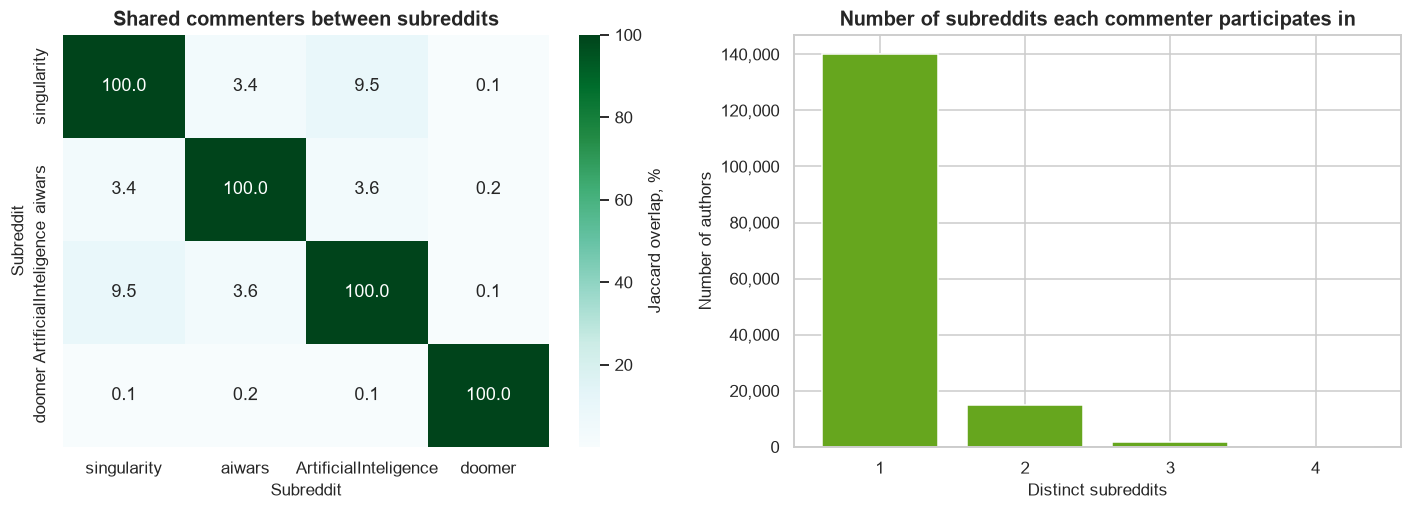

In [13]:
# H9: author overlap between subreddits (Jaccard similarity of commenter sets)
sets = {s: set(comments.loc[(comments["subreddit"]==s) & (comments["author"]!="[deleted]"), "author"]) for s in order}
J = pd.DataFrame({a: {b: len(sets[a]&sets[b])/len(sets[a]|sets[b]) for b in order} for a in order})
n_sub = comments[comments["author"]!="[deleted]"].groupby("author")["subreddit"].nunique().value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.heatmap(J*100, annot=True, fmt=".1f", cmap="BuGn", ax=axes[0], cbar_kws={"label":"Jaccard overlap, %"})
axes[0].set(title="Shared commenters between subreddits", xlabel="Subreddit", ylabel="Subreddit")
axes[1].bar(n_sub.index.astype(str), n_sub.values, color="#66a61e")
axes[1].set(title="Number of subreddits each commenter participates in", xlabel="Distinct subreddits", ylabel="Number of authors")
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v,_: f"{v:,.0f}"))
plt.tight_layout(); plt.show()

> **Observation (H9 – shared audience):** _fill in (which communities share audiences — e.g. is `aiwars` closer to `singularity` or to `ArtificialInteligence`?)._

## 6. Scores and engagement
**H6 (continued).** In debate communities more comments should be downvoted (negative score).

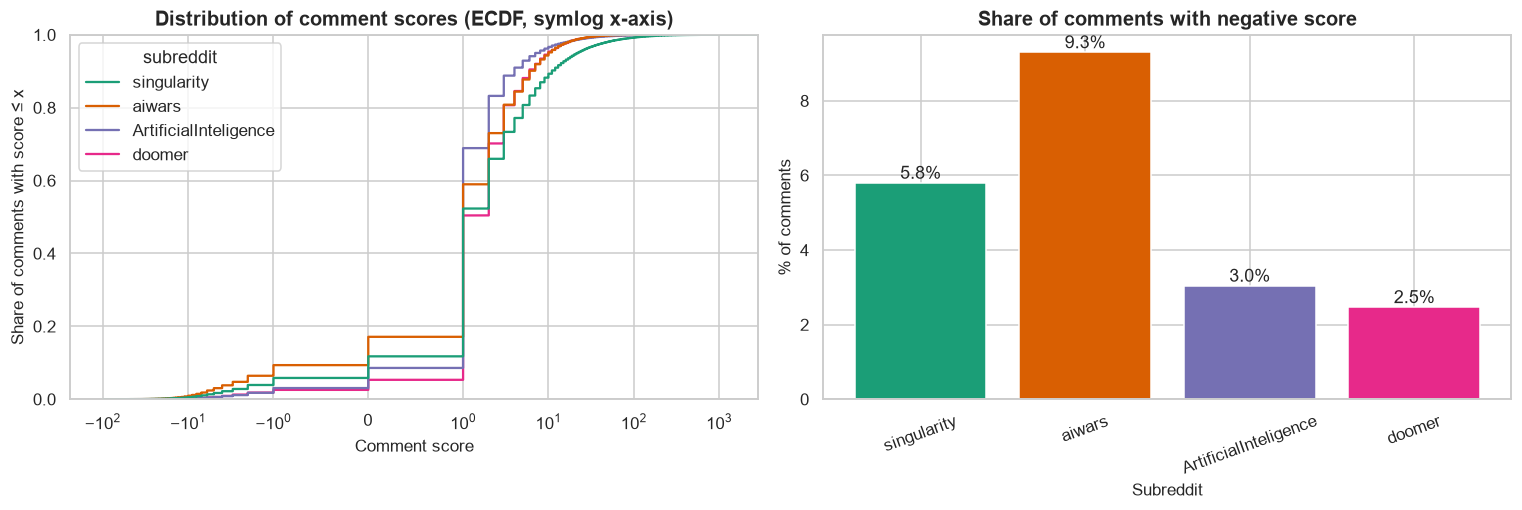

In [14]:
cs = comments.sample(min(400_000, len(comments)), random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

sns.ecdfplot(data=cs, x="score", hue="subreddit", hue_order=order, palette=PAL, ax=axes[0])
axes[0].set_xscale("symlog", linthresh=1)
axes[0].set(title="Distribution of comment scores (ECDF, symlog x-axis)", xlabel="Comment score", ylabel="Share of comments with score ≤ x")
neg = (comments.assign(neg=comments["score"]<0).groupby("subreddit")["neg"].mean().loc[order]*100)
axes[1].bar(neg.index, neg.values, color=[PAL[s] for s in neg.index])
axes[1].set(title="Share of comments with negative score", xlabel="Subreddit", ylabel="% of comments")
axes[1].tick_params(axis="x", rotation=20)
for i, v in enumerate(neg.values): axes[1].text(i, v, f"{v:.1f}%", ha="center", va="bottom")
plt.tight_layout(); plt.show()

> **Observation (H6 – downvoted comments):** _fill in (is `aiwars` the most downvoted? what is the typical comment score?)._

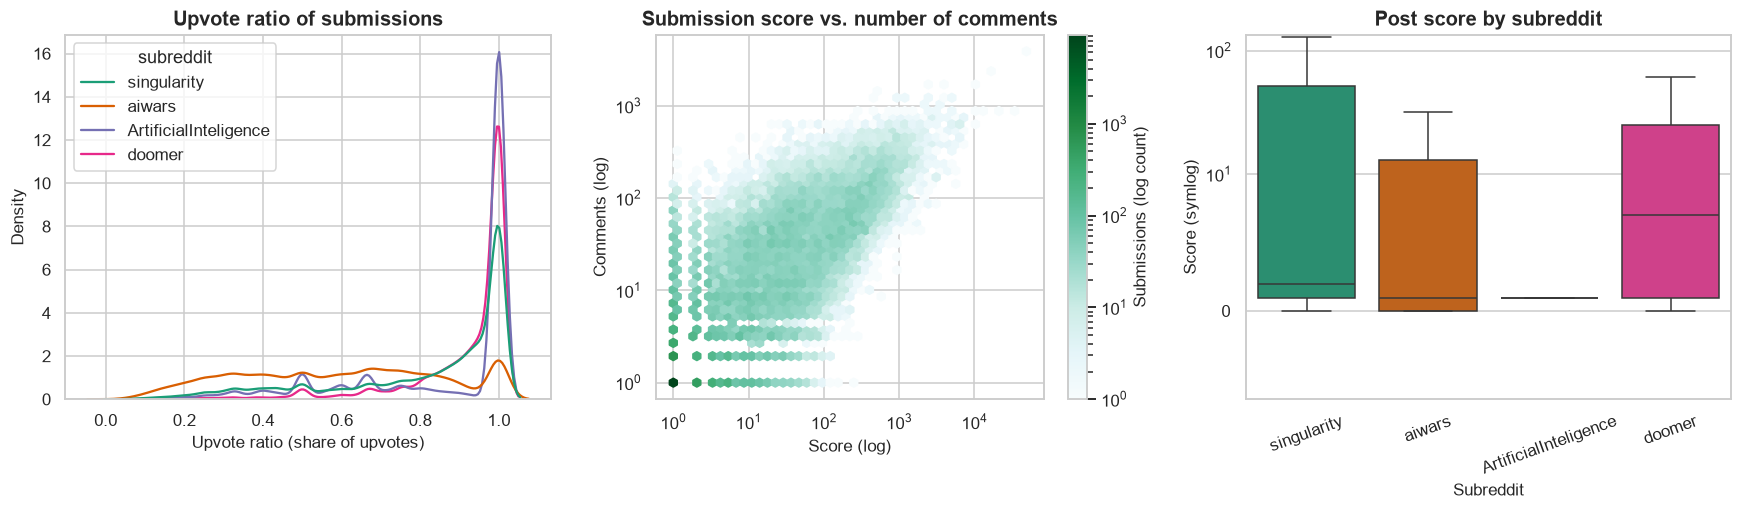

Spearman corr (score, num_comments): 0.426


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
sns.kdeplot(data=subs, x="upvote_ratio", hue="subreddit", hue_order=order, palette=PAL, common_norm=False, ax=axes[0], bw_adjust=.6)
axes[0].set(title="Upvote ratio of submissions", xlabel="Upvote ratio (share of upvotes)", ylabel="Density")

pos = subs[(subs["score"]>0) & (subs["num_comments"]>0)]
hb = axes[1].hexbin(pos["score"], pos["num_comments"], xscale="log", yscale="log", gridsize=45, bins="log", cmap="BuGn", mincnt=1)
plt.colorbar(hb, ax=axes[1], label="Submissions (log count)")
axes[1].set(title="Submission score vs. number of comments", xlabel="Score (log)", ylabel="Comments (log)")

sc = subs.copy(); sc["score_pos"] = sc["score"].clip(lower=0)
sns.boxplot(data=sc, x="subreddit", y="score_pos", order=order, palette=PAL, showfliers=False, ax=axes[2])
axes[2].set_yscale("symlog", linthresh=10)
axes[2].set(title="Post score by subreddit", xlabel="Subreddit", ylabel="Score (symlog)")
axes[2].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
print("Spearman corr (score, num_comments):", round(subs[["score","num_comments"]].corr(method="spearman").iloc[0,1], 3))

> **Observation (controversy & engagement drivers):** _fill in (is a popular post also a heavily discussed one? which subreddit has the most polarised ratios — low upvote_ratio?)._

## 7. Text: length, vocabulary, linked sources
Basic textual descriptors before deeper NLP in week 2 (no word clouds — bar charts of frequencies instead).

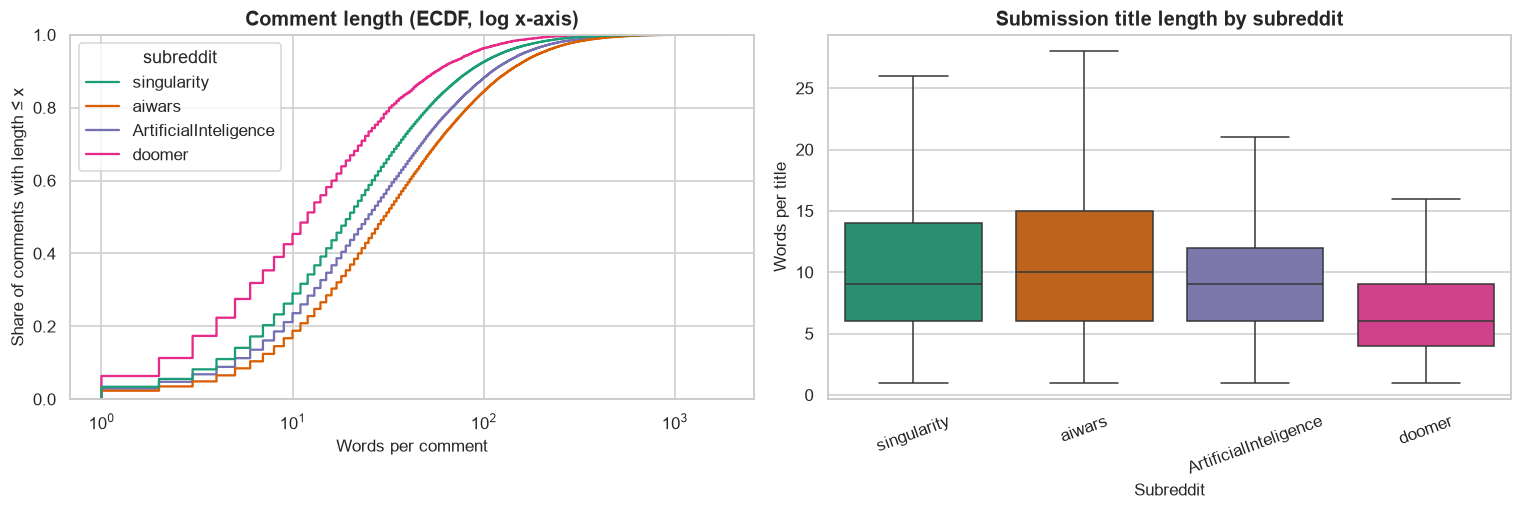

Median words per comment by subreddit:
 subreddit
singularity              20.0
aiwars                   30.0
ArtificialInteligence    25.0
doomer                   12.0


In [16]:
valid = comments[~comments["body"].isin(["[removed]","[deleted]"]) & comments["body"].notna()]
cs2 = valid.sample(min(300_000, len(valid)), random_state=1).copy()
cs2["words"] = cs2["body"].str.split().str.len()
subs["title_words"] = subs["title"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.ecdfplot(data=cs2, x="words", hue="subreddit", hue_order=order, palette=PAL, log_scale=True, ax=axes[0])
axes[0].set(title="Comment length (ECDF, log x-axis)", xlabel="Words per comment", ylabel="Share of comments with length ≤ x")
sns.boxplot(data=subs, x="subreddit", y="title_words", order=order, palette=PAL, showfliers=False, ax=axes[1])
axes[1].set(title="Submission title length by subreddit", xlabel="Subreddit", ylabel="Words per title")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
print("Median words per comment by subreddit:\n", cs2.groupby("subreddit")["words"].median().loc[order].to_string())

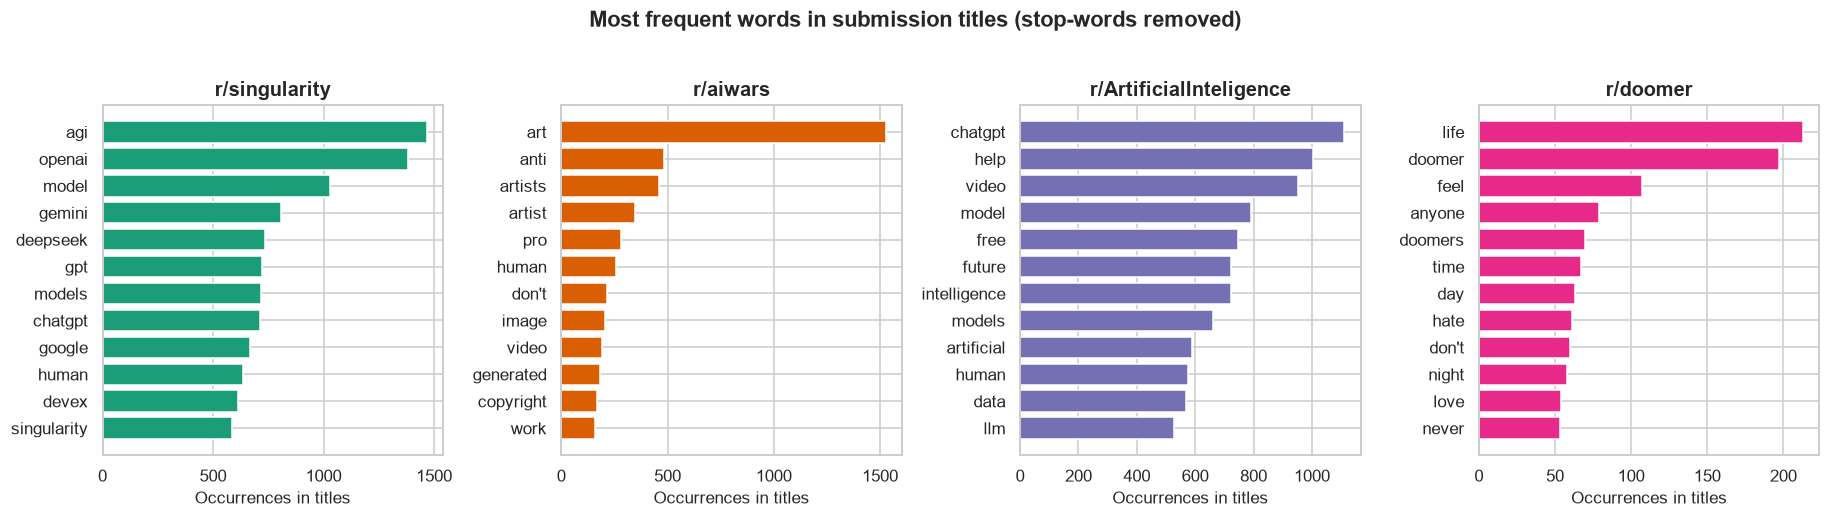

In [17]:
STOP = set('''the and for that this with you are was were have has had not but they their them his her she him its our out about from what when who how why
which would could should will can just like all any more most some than then there these those into over also very much many one two get got your yours ours
been being does did doing done too only own same such here where while because between after before again once off down but now new use used using
people think know don dont doesn isn aren wasn weren didn won wouldn couldn shouldn can't i'm it's that's they're you're we're i've ive thats youre theyre
im say says said want need really even still make made way thing things going well good lot https http www com reddit amp'''.split())
tok = re.compile(r"[a-z][a-z']{2,}")
def top_words(texts, n=12):
    c = Counter()
    for t in texts:
        c.update(w for w in tok.findall(str(t).lower()) if w not in STOP)
    return c.most_common(n)

fig, axes = plt.subplots(1, len(order), figsize=(4.2*len(order), 4.6))
for ax, s in zip(np.atleast_1d(axes), order):
    tw = pd.DataFrame(top_words(subs.loc[subs["subreddit"]==s, "title"]), columns=["word","n"])[::-1]
    ax.barh(tw["word"], tw["n"], color=PAL[s]); ax.set(title=f"r/{s}", xlabel="Occurrences in titles")
fig.suptitle("Most frequent words in submission titles (stop-words removed)", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

> **Observation:** _fill in (which products/companies/terms dominate each community — e.g. model names, company names, 'art', 'artist', 'job'...)._

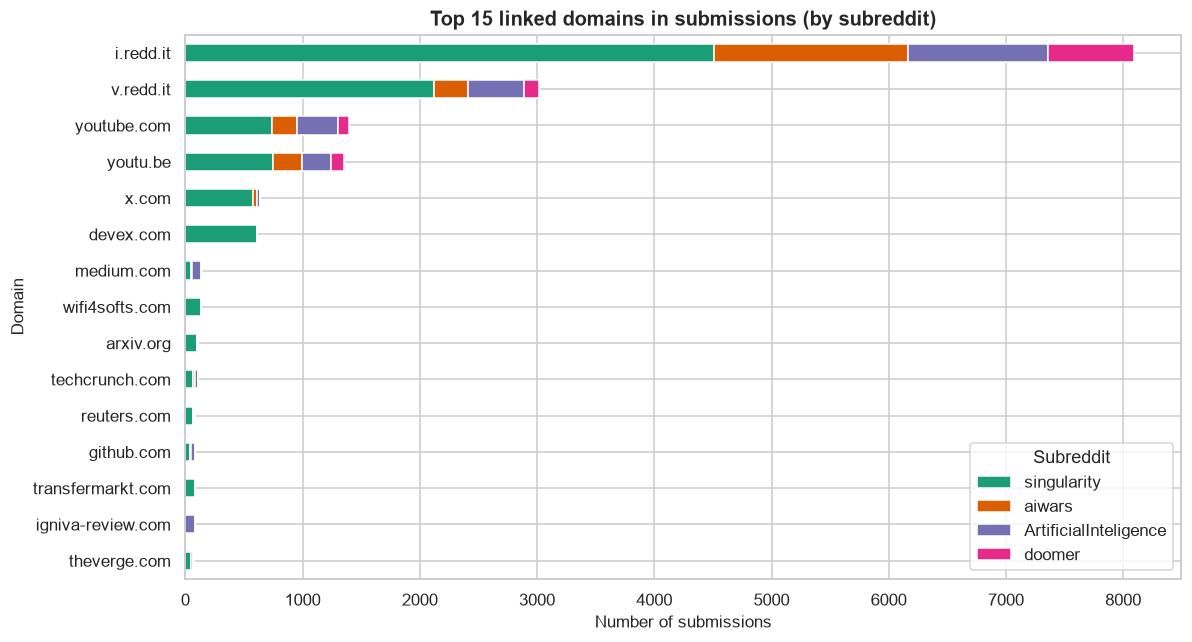

In [18]:
# Where do posts point to? top linked domains (self-posts excluded)
dom = subs["url"].dropna().str.extract(r"https?://(?:www\.)?([^/]+)")[0]
dom = dom[~dom.isin(["reddit.com","old.reddit.com"])]
top_dom = pd.crosstab(dom, subs.loc[dom.index, "subreddit"])[order]
top_dom = top_dom.loc[top_dom.sum(axis=1).sort_values(ascending=False).head(15).index][::-1]
top_dom.plot.barh(stacked=True, figsize=(11, 6), color=[PAL[s] for s in order])
plt.title("Top 15 linked domains in submissions (by subreddit)"); plt.xlabel("Number of submissions"); plt.ylabel("Domain")
plt.legend(title="Subreddit"); plt.tight_layout(); plt.show()

> **Observation:** _fill in (share of image/video hosting `i.redd.it` / `v.redd.it` vs. news sites / X (twitter) / YouTube / arXiv — differences in how each community shares information)._

## 8. Merging submissions and comments
**How and why.** Every comment has `link_id = "t3_" + <submission id>`. We create the key `post_id` for comments (`link_id` without the `t3_` prefix) and join it to `subs.id` to (a) check coverage of the two tables, (b) compare the number of comments we actually have with Reddit's reported `num_comments`, and (c) measure how fast discussion starts after a post. A `left` join from comments is used, since comments whose post was published *before* our window (or removed) have no matching submission — those are kept but flagged.

Comments whose parent submission is in our submissions table: 98.0%


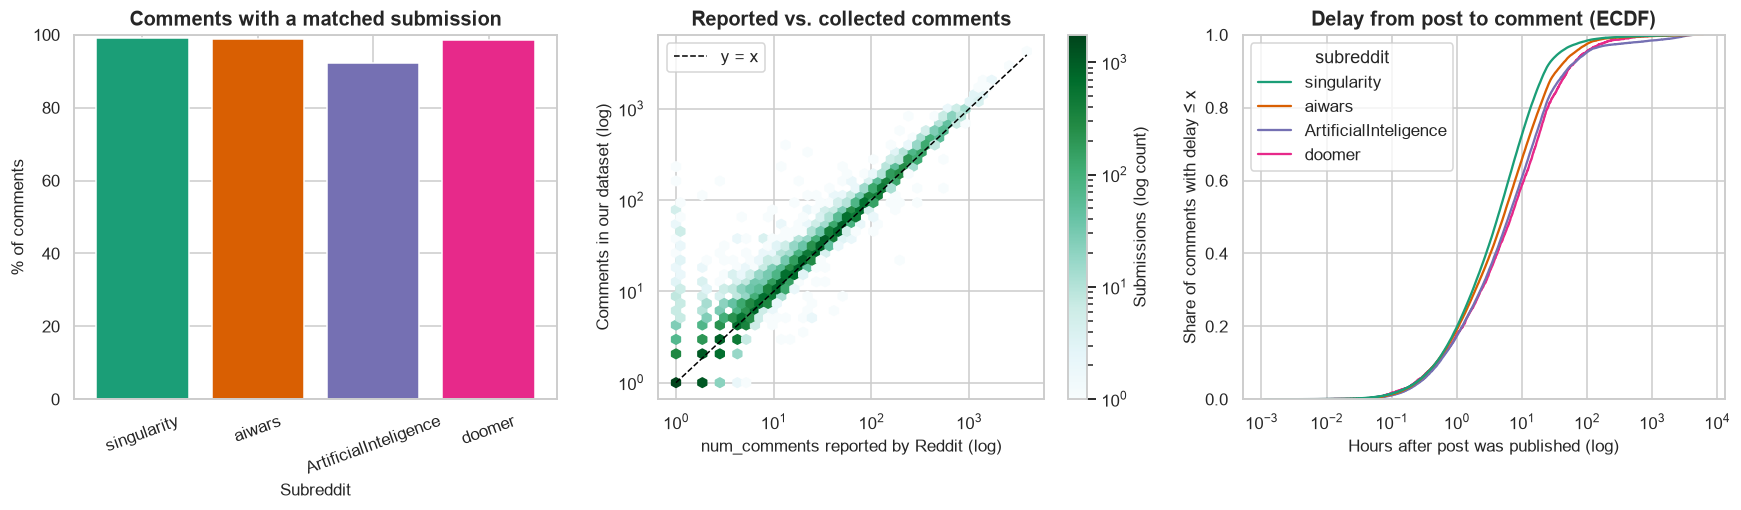

Median delay (hours) by subreddit:
 subreddit
singularity              4.27
aiwars                   5.20
ArtificialInteligence    6.26
doomer                   6.80


In [19]:
comments["post_id"] = comments["link_id"].str.replace("t3_", "", regex=False)
post_time = subs.drop_duplicates("id").set_index("id")["created_utc"]
comments["post_time"] = comments["post_id"].map(post_time)
comments["matched"] = comments["post_time"].notna()
comments["delay_h"] = (comments["created_utc"] - comments["post_time"]).dt.total_seconds()/3600

cov = comments.groupby("subreddit")["matched"].mean().loc[order]*100
print(f"Comments whose parent submission is in our submissions table: {comments['matched'].mean()*100:.1f}%")

observed = comments[comments["matched"]].groupby("post_id").size().rename("observed")
posts = subs.drop_duplicates("id").set_index("id").join(observed).fillna({"observed": 0})

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].bar(cov.index, cov.values, color=[PAL[s] for s in cov.index])
axes[0].set(title="Comments with a matched submission", xlabel="Subreddit", ylabel="% of comments", ylim=(0,100))
axes[0].tick_params(axis="x", rotation=20)

p = posts[(posts["num_comments"]>0) & (posts["observed"]>0)]
hb = axes[1].hexbin(p["num_comments"], p["observed"], xscale="log", yscale="log", gridsize=40, bins="log", cmap="BuGn", mincnt=1)
lim = [1, p["num_comments"].max()]; axes[1].plot(lim, lim, color="black", ls="--", lw=1, label="y = x")
plt.colorbar(hb, ax=axes[1], label="Submissions (log count)"); axes[1].legend()
axes[1].set(title="Reported vs. collected comments", xlabel="num_comments reported by Reddit (log)", ylabel="Comments in our dataset (log)")

dl_all = comments[comments["matched"] & (comments["delay_h"]>0)]
dl = dl_all.sample(n=min(300_000, len(dl_all)), random_state=2)
sns.ecdfplot(data=dl, x="delay_h", hue="subreddit", hue_order=order, palette=PAL, log_scale=True, ax=axes[2])
axes[2].set(title="Delay from post to comment (ECDF)", xlabel="Hours after post was published (log)", ylabel="Share of comments with delay ≤ x")
plt.tight_layout(); plt.show()
print("Median delay (hours) by subreddit:\n", dl.groupby("subreddit")["delay_h"].median().loc[order].round(2).to_string())

> **Observation:** _fill in (coverage % — low coverage means most comments belong to posts older than the window; how complete is our comment collection vs. Reddit's counters; how quickly do threads 'die'?)._

## 9. Preliminary findings and next steps (week 2)
**Already established from the data (HW#2 counts):**
- The dataset has two tables: **65,582 submissions** and **1,617,751 comments** in 4 communities.
- `singularity` is the main source of comments (57.6%), `ArtificialInteligence` of posts (45.6%); `aiwars` is the most "talkative" per post (≈ 52 comments/post vs ≈ 8 in `ArtificialInteligence`).
- `[deleted]` accounts are the single largest "author" (39,567 comments, 772 posts) and are excluded from author analyses; a few accounts post hundreds of submissions (`MetaKnowing` 643, `Gothsim10` 494, `IlustriousTea` 490), suggesting news-curator behaviour.

**To do for the final report:**
1. Fill in observations for every chart above and connect each activity spike to a real-world event (AI model releases, regulation news, AI-art controversies) — **H8**.
2. **H1 / H2:** NLP analysis of the "fatalism paradox" and "AI as religion" — determinism lexicon, sentiment tracking and Word2Vec across the communities.
3. **H3 / H4:** NER extraction for tool vs. user terminology (class conflict), and monthly tracking of "physical threat" words vs. "information degradation" terms (slop / fake) to validate shifting concerns.
4. **Thread structure (H6):** depth of reply chains using `parent_id`; share of top-level vs. nested comments; most controversial posts.
5. **H5 and user dynamics:** deliberate textual imperfections (spelling / slang / readability), newcomers vs. veterans, retention across months, cross-posting authors, bot-like accounts that remain after filtering (H7).